# 01 — Données de la phase 1

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/SerreIA/blob/main/notebooks/01_donnees.ipynb)

Exploration de `data/index.parquet` (docs/02-donnees.md) : effectifs par source, split et
classe, groupes contradictoires écartés, exemples d'images, augmentations fortes et
remplacement de fond (docs/03-classifieur.md §3). Pas de GPU nécessaire. Statistiques
détaillées (déséquilibre, couverture, splits, photométrie, doublons) :
`06_stats_classifieur` (docs/19).

## Paramètres

In [8]:
DATASETS = ["index", "plantvillage", "ccmt", "plantdoc"]
N_EXAMPLES = 8  # images par source / variantes d'augmentation
SEED = 0

## Environnement

In [9]:
# Environnement (PC et Colab) : dépôt, données, sorties (docs/data-drive.md).
# PC : rien n'est installé ; un jeu absent est récupéré du Drive par rclone, sinon la cellule
# s'arrête avec la commande à lancer. Colab : clone du dépôt à REV, installation, données via
# le Drive monté (archives MyDrive/SerreIA/data/*.tar), sorties précédentes restaurées.
import logging
import os
import subprocess
import sys
from pathlib import Path

DRIVE_DIR = "/content/drive/MyDrive/SerreIA"  # Colab : data/*.tar et runs/ ; None : pas de Drive
REPO_URL = "https://github.com/lrivals/SerreIA.git"
REV = "main"
COLAB = "google.colab" in sys.modules

if COLAB:
    ROOT = Path("/content/SerreIA")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "--detach", "FETCH_HEAD"], check=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{ROOT}[vision]"], check=True
    )
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s", force=True)

from tools.notebooks import drive_data  # noqa: E402

if COLAB and DRIVE_DIR:
    drive_data.mount_drive()
    drive_data.restore_all(DRIVE_DIR)
drive_data.ensure(DATASETS, DRIVE_DIR if COLAB else None)

# Colab : tous les cœurs pour le chargement, base MLflow séparée de celle du PC.
ENV_SET = (
    [f"data.num_workers={os.cpu_count()}", f"mlflow.tracking_uri={drive_data.COLAB_MLFLOW}"]
    if COLAB
    else []
)

/content/drive/MyDrive/SerreIA/runs/runs → runs
/content/drive/MyDrive/SerreIA/runs/mlruns/colab → mlruns/colab
index: ready
plantvillage: ready
ccmt: ready
plantdoc: ready


## Index et splits

In [10]:
import pandas as pd
from IPython.display import display

from vision.datasets.build_index import DATA_DIR, INDEX_NAME
from vision.datasets.dataset import load_index

raw = pd.read_parquet(DATA_DIR / INDEX_NAME)
df = load_index(DATA_DIR / INDEX_NAME)
print(f"{len(raw)} images indexées, {len(raw) - len(df)} écartées (groupes contradictoires)")
print(f"{df['espece'].nunique()} espèces, {df['classe'].nunique()} classes, "
      f"{df.loc[df['ambigu'], 'classe'].nunique()} ambiguës")
display(pd.crosstab(df["source"], df["split"], margins=True))

INFO groupes contradictoires : 715 images écartées {'ccmt': 612, 'plantvillage': 64, 'plantdoc': 39}


88135 images indexées, 715 écartées (groupes contradictoires)
16 espèces, 56 classes, 3 ambiguës


split,test,test_xdomain,train,val,All
source,,,,,
ccmt,2453,0,19611,2450,24514
plantdoc,0,8665,0,0,8665
plantvillage,5431,0,43382,5428,54241
All,7884,8665,62993,7878,87420


In [11]:
per_class = pd.crosstab(df["classe"], df["split"])
per_class["total"] = per_class.sum(axis=1)
display(per_class.sort_values("total"))

split,test,test_xdomain,train,val,total
classe,,,,,
pomme_de_terre/sain/sain,15,11,120,15,161
mais/nuisible/chenille_legionnaire,28,0,229,28,285
anacardier/maladie/gommose,39,0,314,39,392
pommier/maladie/rouille,27,178,220,28,453
tomate/virus/enroulement_ccmt,50,0,401,48,499
mais/maladie/cercosporiose,51,78,410,52,591
tomate/virus/mosaique,38,240,298,37,613
pommier/maladie/pourriture_noire,62,0,497,62,621
vigne/sain/sain,43,220,337,43,643


## Exemples par source

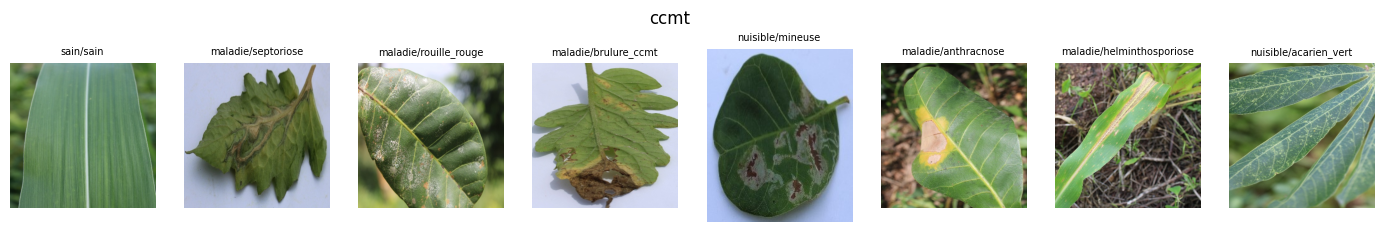

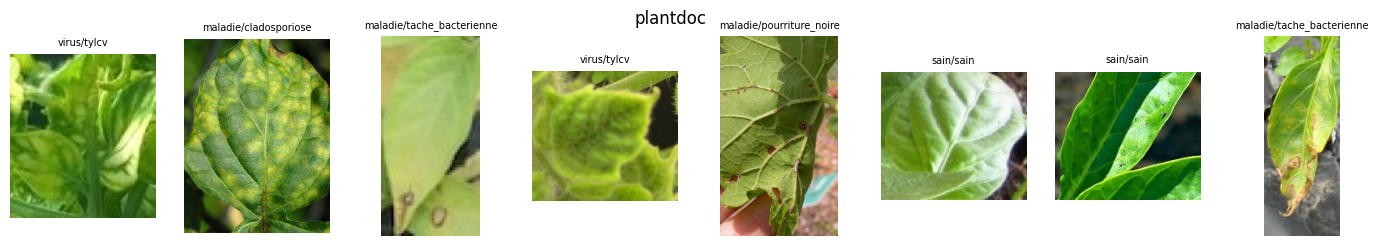

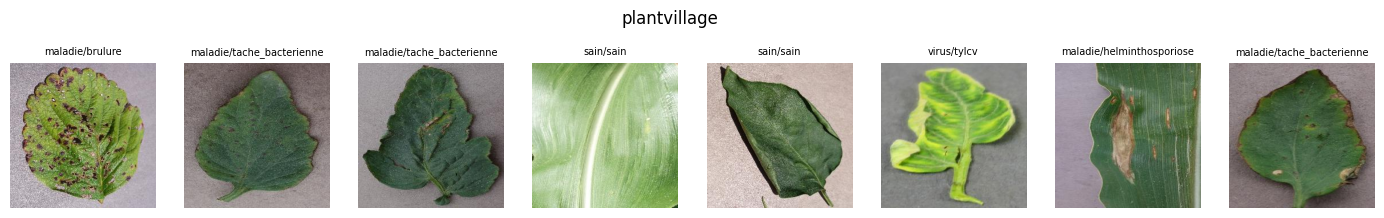

In [12]:
import matplotlib.pyplot as plt

from vision.datasets.dataset import read_rgb

for source, sub in df.groupby("source", observed=True):
    rows = sub.sample(min(N_EXAMPLES, len(sub)), random_state=SEED)
    fig, axes = plt.subplots(1, len(rows), figsize=(2.2 * len(rows), 2.6))
    for ax, (_, r) in zip(axes, rows.iterrows()):
        ax.imshow(read_rgb(DATA_DIR / r["path"]))
        ax.set_title(r["classe"].split("/", 1)[1], fontsize=7)
        ax.axis("off")
    fig.suptitle(source)
    plt.show()

## Augmentations fortes (§3.1)

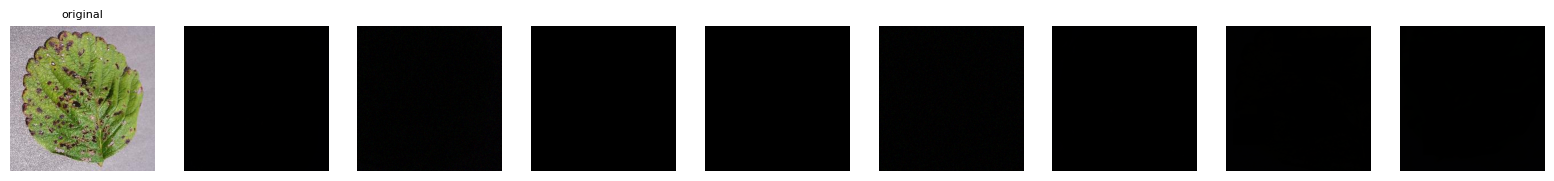

In [13]:
import random

import torch

from vision.datasets.augment import build_transform
from vision.datasets.batch_augment import BatchAugment
from vision.eval.gradcam import denormalize

random.seed(SEED)
torch.manual_seed(SEED)
r = df[df["source"] == "plantvillage"].sample(1, random_state=SEED).iloc[0]
img = read_rgb(DATA_DIR / r["path"])
# Étage CPU (workers : géométrie, ombres, CLAHE) puis étage par batch (GPU à
# l'entraînement, CPU ici : couleur, LED, flou, bruit, JPEG, occlusions).
strong = build_transform("strong", 224)
x = torch.stack([strong(image=img)["image"] for _ in range(N_EXAMPLES)])
x = BatchAugment("strong")(x)
fig, axes = plt.subplots(1, N_EXAMPLES + 1, figsize=(2.2 * (N_EXAMPLES + 1), 2.4))
axes[0].imshow(img)
axes[0].set_title("original", fontsize=8)
for ax, aug in zip(axes[1:], denormalize(x)):
    ax.imshow(aug)
for ax in axes:
    ax.axis("off")
plt.show()

## Remplacement de fond (§3.2)

Nécessite `data/backgrounds/` (jeu `backgrounds`, voir docs/data-drive.md) ; sinon la
cellule l'indique et ne fait rien.

In [14]:
from vision.datasets.augment import BackgroundPaster

if drive_data.ready("backgrounds"):
    masked = df[df["mask_path"].notna()].sample(N_EXAMPLES, random_state=SEED)
    pool = [DATA_DIR / p for p in masked["mask_path"]]
    paster = BackgroundPaster(DATA_DIR / "backgrounds", pool, p=1.0, p_multi=0.5)
    fig, axes = plt.subplots(2, N_EXAMPLES, figsize=(2.2 * N_EXAMPLES, 4.6))
    for k, (_, r) in enumerate(masked.iterrows()):
        img = read_rgb(DATA_DIR / r["path"])
        axes[0, k].imshow(img)
        axes[1, k].imshow(paster(img, read_rgb(DATA_DIR / r["mask_path"])))
    for ax in axes.ravel():
        ax.axis("off")
    plt.show()
else:
    print("data/backgrounds/ absent : aperçu du remplacement de fond ignoré.")

data/backgrounds/ absent : aperçu du remplacement de fond ignoré.
